# PS1 — MNIST Handwritten Digit Classification (CNN)


In [9]:
%pip install --upgrade pip
%pip install tensorflow notebook ipykernel matplotlib numpy pandas scikit-learn seaborn kagglehub

  Using cached pip-26.3-py3-none-any.whl.metadata (4.6 kB)
Using cached pip-26.3-py3-none-any.whl (2.0 MB)
  Attempting uninstall: pip
    Found existing installation: pip 26.2.1
    Uninstalling pip-26.2.1:
      Successfully uninstalled pip-26.2.1
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


  Using cached kagglehub-1.0.3-py3-none-any.whl.metadata (40 kB)
  Using cached certifi-2026.11.20-py3-none-any.whl.metadata (2.5 kB)
  Using cached kagglesdk-0.1.38-py3-none-any.whl.metadata (13 kB)
Using cached kagglehub-1.0.3-py3-none-any.whl (73 kB)
Using cached kagglesdk-0.1.38-py3-none-any.whl (290 kB)
Using cached certifi-2026.11.20-py3-none-any.whl (127 kB)

  Attempting uninstall: certifi

    Found existing installation: certifi 2026.7.22

    Uninstalling certifi-2026.7.22:

      Successfully uninstalled certifi-2026.7.22

   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ---------------------------------------- 3/3 [kagglehub]

Note: you may need to restart the kernel to use updated packages.


In [10]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
BATCH_SIZE = 128
EPOCHS = 15
SAVE_TO_DRIVE = False

keras.utils.set_random_seed(SEED)
print('TensorFlow:', tf.__version__)

TensorFlow: 2.21.0


In [11]:
gpus = tf.config.list_physical_devices('GPU')
for g in gpus:
    tf.config.experimental.set_memory_growth(g, True)
if gpus:
    print('GPU detected:', gpus[0].name)
    try:
        import pynvml
        pynvml.nvmlInit()
        info = pynvml.nvmlDeviceGetMemoryInfo(pynvml.nvmlDeviceGetHandleByIndex(0))
        print(f'VRAM: {info.total / 1024**3:.1f} GB total, {info.free / 1024**3:.1f} GB free')
    except Exception:
        pass
else:
    print('No GPU found. PS1 is light, so a CPU runtime also works (just slower).')

No GPU found. PS1 is light, so a CPU runtime also works (just slower).


In [12]:
OUT_DIR = 'outputs'
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/ps01_mnist'
os.makedirs(OUT_DIR, exist_ok=True)
CKPT_PATH = os.path.join(OUT_DIR, 'best_model.keras')
print('Saving artifacts to:', OUT_DIR)

Saving artifacts to: outputs


## Data


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Train: (60000, 28, 28, 1) Test: (10000, 28, 28, 1)


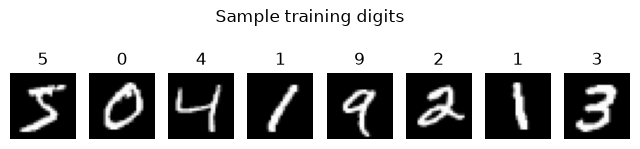

In [13]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
x_train = x_train.astype('float32')[..., None] / 255.0
x_test = x_test.astype('float32')[..., None] / 255.0
print('Train:', x_train.shape, 'Test:', x_test.shape)

plt.figure(figsize=(8, 2))
for i in range(8):
    plt.subplot(1, 8, i + 1)
    plt.imshow(x_train[i].squeeze(), cmap='gray')
    plt.title(str(y_train[i]))
    plt.axis('off')
plt.suptitle('Sample training digits')
plt.show()

## Model


In [14]:
model = keras.Sequential([
    layers.Input((28, 28, 1)),
    layers.Conv2D(32, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax'),
])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

## Training


In [15]:
callbacks = [
    keras.callbacks.ModelCheckpoint(CKPT_PATH, monitor='val_accuracy', save_best_only=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5),
    keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=3, restore_best_weights=True),
]
history = model.fit(
    x_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.1,
    callbacks=callbacks,
    verbose=2,
)

Epoch 1/15
422/422 - 7s - 18ms/step - accuracy: 0.9294 - loss: 0.2371 - val_accuracy: 0.9843 - val_loss: 0.0561 - learning_rate: 0.0010
Epoch 2/15
422/422 - 6s - 15ms/step - accuracy: 0.9789 - loss: 0.0701 - val_accuracy: 0.9880 - val_loss: 0.0396 - learning_rate: 0.0010
Epoch 3/15
422/422 - 6s - 15ms/step - accuracy: 0.9843 - loss: 0.0499 - val_accuracy: 0.9898 - val_loss: 0.0357 - learning_rate: 0.0010
Epoch 4/15
422/422 - 6s - 14ms/step - accuracy: 0.9871 - loss: 0.0407 - val_accuracy: 0.9893 - val_loss: 0.0340 - learning_rate: 0.0010
Epoch 5/15
422/422 - 6s - 14ms/step - accuracy: 0.9897 - loss: 0.0340 - val_accuracy: 0.9908 - val_loss: 0.0299 - learning_rate: 0.0010
Epoch 6/15
422/422 - 6s - 14ms/step - accuracy: 0.9905 - loss: 0.0281 - val_accuracy: 0.9905 - val_loss: 0.0346 - learning_rate: 0.0010
Epoch 7/15
422/422 - 6s - 14ms/step - accuracy: 0.9921 - loss: 0.0246 - val_accuracy: 0.9922 - val_loss: 0.0296 - learning_rate: 0.0010
Epoch 8/15
422/422 - 10s - 24ms/step - accuracy:

## Evaluation


Test accuracy: 0.9915   Test loss: 0.0256


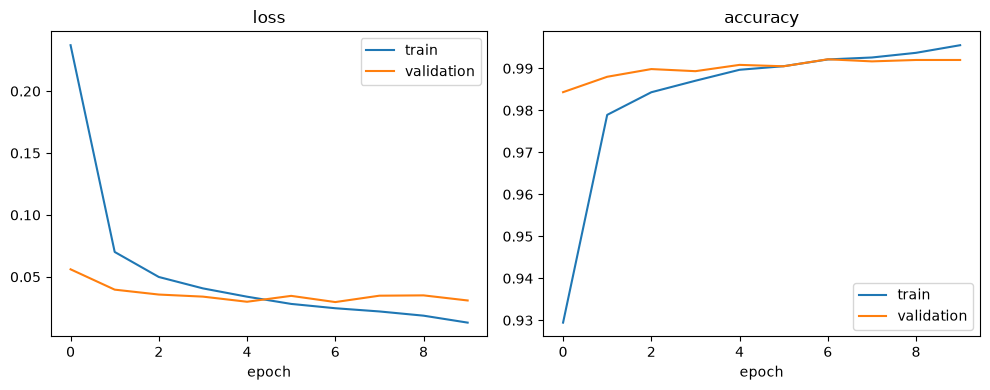

In [16]:
loss, acc = model.evaluate(x_test, y_test, verbose=0)
print(f'Test accuracy: {acc:.4f}   Test loss: {loss:.4f}')

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for i, metric in enumerate(['loss', 'accuracy']):
    ax[i].plot(history.history[metric], label='train')
    ax[i].plot(history.history['val_' + metric], label='validation')
    ax[i].set_title(metric)
    ax[i].set_xlabel('epoch')
    ax[i].legend()
plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

           0     0.9919    0.9980    0.9949       980
           1     0.9921    1.0000    0.9961      1135
           2     0.9932    0.9971    0.9952      1032
           3     0.9940    0.9891    0.9916      1010
           4     0.9919    0.9959    0.9939       982
           5     0.9811    0.9899    0.9855       892
           6     0.9958    0.9864    0.9911       958
           7     0.9961    0.9883    0.9922      1028
           8     0.9818    0.9959    0.9888       974
           9     0.9959    0.9732    0.9845      1009

    accuracy                         0.9915     10000
   macro avg     0.9914    0.9914    0.9914     10000
weighted avg     0.9915    0.9915    0.9915     10000



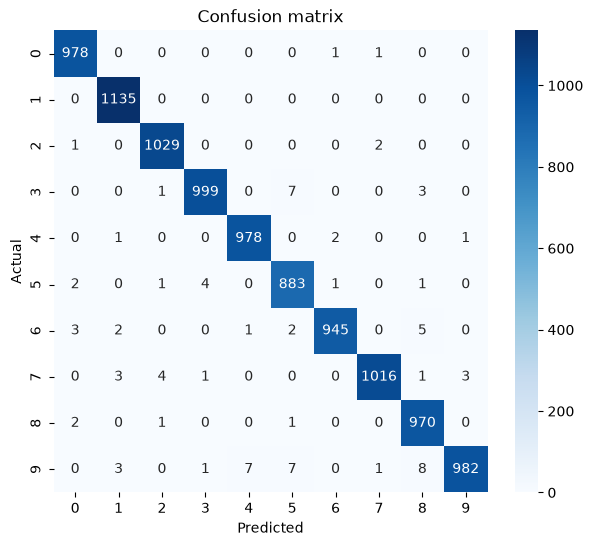

In [17]:
y_pred = model.predict(x_test, verbose=0).argmax(axis=1)
print(classification_report(y_test, y_pred, digits=4))

plt.figure(figsize=(7, 6))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion matrix')
plt.show()

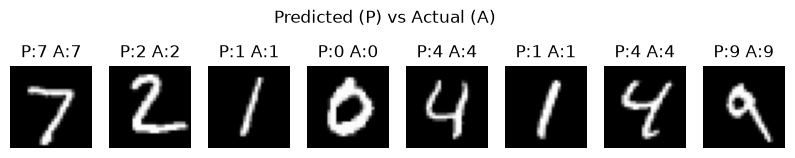

In [18]:
plt.figure(figsize=(10, 2))
for i in range(8):
    plt.subplot(1, 8, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap='gray')
    plt.title(f'P:{y_pred[i]} A:{y_test[i]}')
    plt.axis('off')
plt.suptitle('Predicted (P) vs Actual (A)')
plt.show()

## Single-image demo & save


Actual: 7   Predicted: 7   Confidence: 1.000


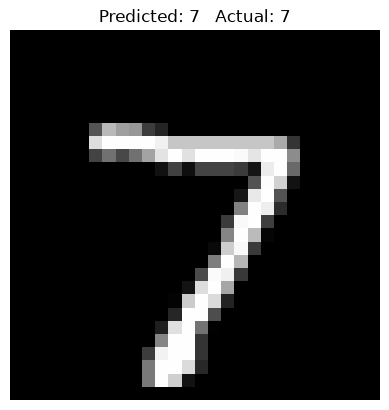

In [19]:
image_index = 0
test_image = x_test[image_index]
true_label = int(y_test[image_index])
probs = model.predict(np.expand_dims(test_image, 0), verbose=0)[0]
predicted_label = int(probs.argmax())
print(f'Actual: {true_label}   Predicted: {predicted_label}   Confidence: {probs[predicted_label]:.3f}')
plt.imshow(test_image.squeeze(), cmap='gray')
plt.title(f'Predicted: {predicted_label}   Actual: {true_label}')
plt.axis('off')
plt.show()

In [20]:
final_path = os.path.join(OUT_DIR, 'final_model.keras')
model.save(final_path)
pd.DataFrame(history.history).to_csv(os.path.join(OUT_DIR, 'training_log.csv'), index=False)
print('Saved best checkpoint:', CKPT_PATH)
print('Saved final model:', final_path)

Saved best checkpoint: outputs\best_model.keras
Saved final model: outputs\final_model.keras
